# Scam Drift
**Question.** Does a scam filter trained on 2012-era SMS spam still protect an elderly grandparent from 2020s smishing?
Which scam types slip through? Can we fix it without flooding them with false alarms on genuine modern texts
(bank one-time codes, delivery notices, pharmacy and doctor reminders)?

**User:** an elderly grandparent, or the family member who sets up their phone. **Decision:** warn before tapping a link.

This notebook runs the same code as `src/scam_drift.py`. It works locally and in Google Colab.
This project is a prototype and is not financial advice.

## 0. Setup
Install packages (Colab only), download both public datasets if missing, and write the synthetic benign-twins test file if missing.

In [1]:
import os, sys, io, zipfile, urllib.request
from pathlib import Path
if "google.colab" in sys.modules:
    !pip -q install pandas==3.1.1 scikit-learn==1.9.1 matplotlib joblib  # the versions used for the published numbers
Path("data/raw").mkdir(parents=True, exist_ok=True)
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
IMC_URL = "https://raw.githubusercontent.com/reportsmishing/Smishing-Dataset-IMC25/main/dataset/final_dataset_output.csv"
if not Path("data/raw/SMSSpamCollection").exists():
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(UCI_URL).read())).extract("SMSSpamCollection", "data/raw")
if not Path("data/raw/imc25_smishing.csv").exists():
    urllib.request.urlretrieve(IMC_URL, "data/raw/imc25_smishing.csv")
TWINS_CSV = 'text,label,category,source\nYour First Harbor Bank verification code is 482913. It expires in 10 minutes. We will never call or text to ask for this code.,0,bank_otp,synthetic (written with AI assistance for this project)\n"482913 is your one-time passcode to sign in. Do not share it with anyone, including bank staff.",0,bank_otp,synthetic (written with AI assistance for this project)\n"Maple Credit Union: Use code 730245 to confirm your login. If you did not try to sign in, call the number on the back of your card.",0,bank_otp,synthetic (written with AI assistance for this project)\nYour security code is 118274. Never share this code. Our staff will never ask you for it.,0,bank_otp,synthetic (written with AI assistance for this project)\nG-552781 is your verification code.,0,bank_otp,synthetic (written with AI assistance for this project)\nYour code to approve the payment of $45.20 to City Water is 663019. Don\'t share it.,0,bank_otp,synthetic (written with AI assistance for this project)\nRiverside Bank: Your one-time code is 904416. Valid for 5 minutes. Reply HELP for help.,0,bank_otp,synthetic (written with AI assistance for this project)\n"Use 271839 to verify your new device. If this wasn\'t you, you can ignore this message.",0,bank_otp,synthetic (written with AI assistance for this project)\nYour login code is 3391. Enter it in the app to continue.,0,bank_otp,synthetic (written with AI assistance for this project)\nHealth portal: your sign-in code is 845120. It will expire in 15 minutes.,0,bank_otp,synthetic (written with AI assistance for this project)\nFirst Harbor Bank Fraud Alert: Did you use your card ending 4821 for $62.10 at Corner Grocery on Nov 3? Reply YES or NO. We will never ask for your PIN or code.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Maple Credit Union: We declined a card purchase of $899.00. If this was you, please try again. If not, call us at the number on the back of your card.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour debit card ending 1190 was used for $20.00 at a gas station. No action needed if this was you.,0,bank_alert,synthetic (written with AI assistance for this project)\nLow balance alert: Your checking account ending 5532 is below $100.00.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Direct deposit of $1,245.67 received in your checking account ending 5532.",0,bank_alert,synthetic (written with AI assistance for this project)\nReminder: your credit card payment of $85.00 is due on Nov 25. Log in to your app to pay. Do not reply to this message.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Riverside Bank: A new payee was added to your account today. If you did not do this, call us using the number on your statement.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour monthly statement is ready. Sign in to the mobile app to view it.,0,bank_alert,synthetic (written with AI assistance for this project)\nSecurity notice: we will never text you a link asking for your password or one-time code.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Your pension payment of $1,512.00 was deposited today.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour package from Oak Street Books was delivered to your front porch at 2:14 PM.,0,delivery,synthetic (written with AI assistance for this project)\nYour parcel will arrive tomorrow between 10am and 2pm. No action needed.,0,delivery,synthetic (written with AI assistance for this project)\nOut for delivery: your order #48211 will arrive today by 8pm.,0,delivery,synthetic (written with AI assistance for this project)\nWe left your package with your neighbour at number 12.,0,delivery,synthetic (written with AI assistance for this project)\nYour order has shipped. Track it at https://www.oakstreetbooks.com/orders,0,delivery,synthetic (written with AI assistance for this project)\nDelivery update: your parcel is delayed due to weather and will arrive Friday. We are sorry for the delay.,0,delivery,synthetic (written with AI assistance for this project)\nYour grocery order will arrive between 4pm and 5pm today. Your driver is Sam.,0,delivery,synthetic (written with AI assistance for this project)\nYour prescription delivery is on the way and will arrive this afternoon. Someone must sign for it.,0,delivery,synthetic (written with AI assistance for this project)\nPackage delivered to your mailbox. Thank you for shopping with us.,0,delivery,synthetic (written with AI assistance for this project)\nYour return has been received. Your refund of $24.99 will appear on your card in 3-5 days.,0,delivery,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your prescription is ready for pickup at our Main Street store. Reply STOP to opt out.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour refill for prescription #2231445 is ready. It will be held for 7 days.,0,pharmacy,synthetic (written with AI assistance for this project)\nReminder: it is time to refill your blood pressure medication. Call us or use the app to request a refill.,0,pharmacy,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your flu shot appointment is tomorrow at 10:30 AM. Please bring your insurance card.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour prescription could not be filled because it needs a new authorisation from your doctor. We have contacted your doctor\'s office.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour prescription order is being processed. We will text you when it is ready.,0,pharmacy,synthetic (written with AI assistance for this project)\nPharmacy reminder: your medication was not picked up and will be returned to stock in 2 days.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour copay for today\'s pickup is $10.00. Pay at the counter.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour vaccine record is available. Ask the pharmacist if you need a printed copy.,0,pharmacy,synthetic (written with AI assistance for this project)\nMaple Pharmacy is closed on Thursday for the holiday. Our other store is open 9am to 5pm.,0,pharmacy,synthetic (written with AI assistance for this project)\n"Reminder: you have an appointment with Dr. Patel on Tuesday, Nov 12 at 9:00 AM. Reply C to confirm or R to reschedule.",0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Please arrive 15 minutes early for your appointment tomorrow and bring a list of your medicines.,0,medical,synthetic (written with AI assistance for this project)\nYour test results are available at https://portal.lakesideclinic.org or you can call the clinic.,0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your eye exam is booked for Monday at 2:30 PM.,0,medical,synthetic (written with AI assistance for this project)\nDental reminder: your cleaning is on Friday at 11 AM. Call 555-0142 to change it.,0,medical,synthetic (written with AI assistance for this project)\nYour doctor has sent you a message. Please sign in to the patient portal to read it.,0,medical,synthetic (written with AI assistance for this project)\nHearing clinic: your new hearing aid batteries are ready to collect at the front desk.,0,medical,synthetic (written with AI assistance for this project)\nThis is a reminder to get your annual checkup. Call the office to book a time that suits you.,0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your appointment has been cancelled because the doctor is unwell. We will call you to rebook.,0,medical,synthetic (written with AI assistance for this project)\nPhysical therapy reminder: your session is tomorrow at 1 PM. Wear comfortable clothes.,0,medical,synthetic (written with AI assistance for this project)\nCity Water: Your bill of $48.30 is due on Nov 28. You can pay by phone or at the office.,0,utility_other,synthetic (written with AI assistance for this project)\nYour electricity bill is ready. View it at https://www.brightpower.com/account,0,utility_other,synthetic (written with AI assistance for this project)\nYour phone bill of $35.00 was paid. Thank you.,0,utility_other,synthetic (written with AI assistance for this project)\nPower outage in your area. Crews are working and expect power back by 6 PM.,0,utility_other,synthetic (written with AI assistance for this project)\nLibrary: The book you reserved is ready for pickup. It will be held for 7 days.,0,utility_other,synthetic (written with AI assistance for this project)\nYour car is ready for pickup at Main Street Auto. Total: $212.40.,0,utility_other,synthetic (written with AI assistance for this project)\nSenior centre: Bingo is moved to Wednesday at 2 PM this week. See you there!,0,utility_other,synthetic (written with AI assistance for this project)\nYour new mobile plan starts on Dec 1. No action is needed.,0,utility_other,synthetic (written with AI assistance for this project)\nTown council: Trash pickup is delayed by one day this week because of the holiday.,0,utility_other,synthetic (written with AI assistance for this project)\nYour home insurance renewal documents have been mailed to you. Call your agent with any questions.,0,utility_other,synthetic (written with AI assistance for this project)\n"First Harbor Bank: Someone tried to sign in to your account. To cancel, reply with the code we just sent you.",1,bank_otp,synthetic (written with AI assistance for this project)\nThis is your bank\'s fraud team. We sent you a code to verify your identity. Please read it back to us to stop the transfer.,1,bank_otp,synthetic (written with AI assistance for this project)\nYour account will be locked. Share the 6-digit code you received with our agent to keep it open.,1,bank_otp,synthetic (written with AI assistance for this project)\n"Maple Credit Union: Your verification code is 730245. If you did not request this, call 1-800-555-0199 immediately to cancel.",1,bank_otp,synthetic (written with AI assistance for this project)\nVerify your account now: enter your one-time code at http://firstharbor-secure-login.com,1,bank_otp,synthetic (written with AI assistance for this project)\nWe noticed unusual activity. Reply with your code and PIN to confirm it is you.,1,bank_otp,synthetic (written with AI assistance for this project)\n"Your payment of $950.00 to John is pending. If this wasn\'t you, tell us the code we sent to cancel it.",1,bank_otp,synthetic (written with AI assistance for this project)\nFirst Harbor Bank Fraud Alert: Your card has been suspended due to suspicious activity. Verify now at http://fhb-verify-card.net,1,bank_alert,synthetic (written with AI assistance for this project)\n"Maple Credit Union: A charge of $899.00 was made at Electronics World. If not you, call 1-888-555-0123 now.",1,bank_alert,synthetic (written with AI assistance for this project)\nURGENT: Your bank account has been frozen. Click http://bit.ly/unlock-acct to restore access.,1,bank_alert,synthetic (written with AI assistance for this project)\nYour debit card ending 1190 has been blocked. Update your details within 24 hours: http://card-unlock-help.com,1,bank_alert,synthetic (written with AI assistance for this project)\nLow balance alert: we could not process your pension payment. Confirm your bank details at http://pension-update.info,1,bank_alert,synthetic (written with AI assistance for this project)\nSecurity notice: your online banking will be deactivated today unless you confirm your details at http://riverside-bank-secure.co,1,bank_alert,synthetic (written with AI assistance for this project)\nYour refund of $312.50 is waiting. Claim it now at http://refund-claim-center.com,1,bank_alert,synthetic (written with AI assistance for this project)\nYour package could not be delivered due to an incomplete address. Update it here: http://parcel-redelivery-help.com,1,delivery,synthetic (written with AI assistance for this project)\nDelivery failed. A $1.99 redelivery fee is required. Pay now at http://post-fee-pay.com or your parcel will be returned.,1,delivery,synthetic (written with AI assistance for this project)\nOut for delivery: your order #48211 is on hold. Confirm your details at http://track-order-status.net,1,delivery,synthetic (written with AI assistance for this project)\nWe tried to deliver your parcel today. Reschedule within 24 hours: http://bit.ly/resched-pkg,1,delivery,synthetic (written with AI assistance for this project)\nYour parcel is held at customs. Pay the $3.00 fee to release it: http://customs-release-fee.com,1,delivery,synthetic (written with AI assistance for this project)\nYour grocery order is delayed. Click here to get a $50 voucher for the trouble: http://freshvoucher.win,1,delivery,synthetic (written with AI assistance for this project)\nYour return could not be processed. Verify your card at http://returns-verify.com to receive your refund.,1,delivery,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your prescription is on hold. Confirm your insurance details at http://rx-hold-confirm.com,1,pharmacy,synthetic (written with AI assistance for this project)\nYour health insurance card has expired. Get a new card today by confirming your details at http://health-card-renew.com,1,pharmacy,synthetic (written with AI assistance for this project)\nCongratulations! You qualify for free diabetic supplies. Claim now: http://free-meds-claim.com,1,pharmacy,synthetic (written with AI assistance for this project)\nPharmacy reminder: your medication order failed. Update payment within 12 hours: http://rx-payment-update.net,1,pharmacy,synthetic (written with AI assistance for this project)\nGet your prescription drugs 80% off without a prescription. Order now: http://cheap-meds-online.biz,1,pharmacy,synthetic (written with AI assistance for this project)\nYour flu shot appointment requires a $25 deposit. Pay here to keep your slot: http://vaccine-slot-pay.com,1,pharmacy,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your test results show a problem. Log in now to see them: http://lakeside-results-portal.co,1,medical,synthetic (written with AI assistance for this project)\n"Your appointment has been cancelled. To rebook, confirm your Social Security number at http://clinic-rebook.info",1,medical,synthetic (written with AI assistance for this project)\nYour health insurance will stop tomorrow. Call 1-877-555-0144 now to keep your coverage.,1,medical,synthetic (written with AI assistance for this project)\nYou are eligible for a free medical alert device. Reply YES to claim yours today!,1,medical,synthetic (written with AI assistance for this project)\nYour doctor has sent you a message. Sign in with your bank details to read it: http://patient-msg-login.com,1,medical,synthetic (written with AI assistance for this project)\nHearing aid recall: claim your free replacement now at http://hearing-recall-claim.com,1,medical,synthetic (written with AI assistance for this project)\nCity Water: Your water will be disconnected today due to an unpaid bill. Pay immediately at http://citywater-pay-now.com,1,utility_other,synthetic (written with AI assistance for this project)\nYour electricity will be shut off in 2 hours. Call 1-866-555-0177 to pay now.,1,utility_other,synthetic (written with AI assistance for this project)\nYour phone bill payment failed. Update your card at http://mobile-bill-update.com to avoid suspension.,1,utility_other,synthetic (written with AI assistance for this project)\n"Hi Grandma, it\'s me. I lost my phone and I\'m in trouble. Can you send $500 in gift cards? Don\'t tell Mum.",1,utility_other,synthetic (written with AI assistance for this project)\n"You have won $1,000,000 in the senior lottery! Claim your prize at http://senior-lotto-winner.com",1,utility_other,synthetic (written with AI assistance for this project)\nTown council: you have an unpaid parking fine. Pay within 24 hours to avoid court: http://council-fines-pay.com,1,utility_other,synthetic (written with AI assistance for this project)\nYour home insurance has lapsed. Renew now with 50% off: http://insure-renew-deal.com,1,utility_other,synthetic (written with AI assistance for this project)\n'
if not Path("data/benign_twins.csv").exists():
    Path("data/benign_twins.csv").write_text(TWINS_CSV, encoding="utf-8")
import hashlib
EXPECTED_SHA256 = {"data/raw/SMSSpamCollection": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
                   "data/raw/imc25_smishing.csv": "1bbd1e9e82c3ea023112207b80da268a5c4a07d2353c2b0898360ab037fa9a64"}
for f, h in EXPECTED_SHA256.items():
    ok = hashlib.sha256(Path(f).read_bytes()).hexdigest() == h
    print(f, "sha256 OK" if ok else "WARNING: file differs from the version used for the published numbers")
print(sorted(os.listdir("data/raw")))

data/raw/SMSSpamCollection sha256 OK
data/raw/imc25_smishing.csv sha256 OK
['SMSSpamCollection', 'extra', 'imc25_smishing.csv', 'readme', 'smsspam.zip']


## 1. Library code
This cell is the content of `src/scam_drift.py` (without the command-line entry point). It defines normalisation, data loading, the time split, the models, the threshold rule and the metrics.

In [2]:
"""Scam Drift: does a 2012-era SMS spam filter still protect a grandparent from 2020s smishing?

Run end to end (seeded) from the project root:
    python src/scam_drift.py

Outputs: results/metrics.json, results/*.csv, figures/*.png, models/*.joblib.
Importing this module does NOT run the pipeline (app.py imports normalise/explain from here).
"""
from __future__ import annotations

import html
import json
import os
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
DATA_RAW = ROOT / "data" / "raw"
UCI_PATH = DATA_RAW / "SMSSpamCollection"
IMC_PATH = DATA_RAW / "imc25_smishing.csv"
TWINS_PATH = ROOT / "data" / "benign_twins.csv"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
MODELS = ROOT / "models"

# Cost model for the grandparent: a missed scam costs 5x a false alarm.
COST_FN = 5.0
COST_FP = 1.0
# Time split: modern scams dated up to and including this year may be used for training the fix.
TRAIN_LAST_YEAR = 2021

# ---------------------------------------------------------------------------
# 1. Normalisation (applied identically to every source)
# ---------------------------------------------------------------------------
# Placeholder tokens found in either dataset -> one shared vocabulary.
# UCI uses HTML-escaped placeholders such as &lt;#&gt; and &lt;DECIMAL&gt;.
PLACEHOLDER_MAP = {
    "URL": " tok_url ", "IP_ADDRESS": " tok_url ",
    "PHONE_NUMBER": " tok_phone ",
    "EMAIL_ADDRESS": " tok_email ", "EMAIL": " tok_email ",
    "DATE_TIME": " tok_date ", "TIME": " tok_date ",
    # Named entities (people, brands, places) were removed by the IMC25 authors.
    # UCI has no equivalent tag, so we delete the tag instead of creating a dataset-only token.
    "NAMED_ENTITY": " ", "LOCATION": " ", "NRP": " ", "NAME": " ",
    # Presidio-style ID tags mostly fire on long numbers and codes -> generic number.
    "US_DRIVER_LICENSE": " tok_num ", "US_BANK_NUMBER": " tok_num ", "UK_NHS": " tok_num ",
    "US_PASSPORT": " tok_num ", "US_SSN": " tok_num ", "US_ITIN": " tok_num ",
    "CREDIT_CARD": " tok_num ", "IBAN_CODE": " tok_num ", "MEDICAL_LICENSE": " tok_num ",
    "CRYPTO": " tok_num ", "NUMERO_COLIS": " tok_num ", "#": " tok_num ", "DECIMAL": " tok_num ",
}
_PH_RE = re.compile(r"<([A-Z_#]+)>")
_OBFUSCATED_DOT = re.compile(r"\s?[\(\[]\.[\)\]]\s?")
_EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
_TLDS = ("com|net|org|co|uk|ly|info|biz|io|me|us|in|gov|xyz|top|site|online|link|app|cc|ru|cn|de|"
         "ca|au|tk|ml|ga|cf|gq|shop|club|live|vip|icu|buzz|win|ws|eu|es|fr|nl|it|id|my|ph|sg|to|gl")
_URL_RE = re.compile(
    r"(?:https?://\S+|www\.\S+|\b[\w-]+(?:\.[\w-]+)*\.(?:" + _TLDS + r")\b(?:/\S*)?)", re.I)
_MONEY_RE = re.compile(
    r"(?:[£$€₹¥]|\b(?:rs|inr|usd|gbp|eur|rm|aud|cad)\.?)\s?\d[\d,]*(?:\.\d+)?"
    r"|\b\d[\d,]*(?:\.\d+)?\s?(?:pounds|dollars|euros|usd|gbp|eur|pence|ppm|p)\b"
    r"|\b\d[\d,]*(?:\.\d+)?\s?[£$€₹¥]", re.I)  # suffix symbols, e.g. "60$"
_MONTHS = "january|february|march|april|june|july|august|september|october|november|december"
_MON_ABBR = "jan|feb|mar|apr|may|jun|jul|aug|sep|sept|oct|nov|dec"
_DATE_RE = re.compile(
    r"\b\d{1,2}[/.-]\d{1,2}[/.-]\d{2,4}\b"
    r"|\b\d{1,2}:\d{2}(?::\d{2})?\s?(?:[ap]\.?m\.?)?\b"
    r"|\b\d{1,2}\s?(?:[ap]\.?m\.?)\b"
    r"|\b\d{1,2}(?:st|nd|rd|th)?\s+(?:" + _MON_ABBR + r")[a-z]*\b"
    r"|\b(?:" + _MON_ABBR + r")[a-z]*\s+\d{1,2}(?:st|nd|rd|th)?\b"
    r"|\b(?:" + _MONTHS + r")\b"
    r"|\b(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b"
    r"|\b(?:today|tomorrow|tonight|yesterday)\b", re.I)
_PHONE_RE = re.compile(r"\+?\(?\d[\d\s\-()]{5,}\d")
_NUM_RE = re.compile(r"\d+(?:[.,]\d+)*")
_WS_RE = re.compile(r"\s+")


def _ph_sub(m: re.Match) -> str:
    tag = m.group(1)
    return PLACEHOLDER_MAP.get(tag, " " + tag.lower() + " ")


def normalise(text: str) -> str:
    """Map URLs, phones, emails, money, dates and numbers to shared tokens, then lowercase."""
    if not isinstance(text, str):
        return ""
    t = html.unescape(text)
    t = _PH_RE.sub(_ph_sub, t)
    t = _OBFUSCATED_DOT.sub(".", t)
    t = _EMAIL_RE.sub(" tok_email ", t)
    t = _URL_RE.sub(" tok_url ", t)
    t = _MONEY_RE.sub(" tok_money ", t)
    t = _DATE_RE.sub(" tok_date ", t)

    def _phone(m: re.Match) -> str:
        digits = re.sub(r"\D", "", m.group(0))
        return " tok_phone " if len(digits) >= 7 else m.group(0)

    t = _PHONE_RE.sub(_phone, t)
    t = _NUM_RE.sub(" tok_num ", t)
    t = t.lower()
    return _WS_RE.sub(" ", t).strip()


# ---------------------------------------------------------------------------
# 2. Data loading
# ---------------------------------------------------------------------------
def _read_text(path: Path) -> str:
    raw = path.read_bytes()
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return raw.decode(enc)
        except UnicodeDecodeError:
            continue
    return raw.decode("utf-8", errors="replace")


def load_uci() -> pd.DataFrame:
    rows = []
    for line in _read_text(UCI_PATH).splitlines():
        if "\t" not in line:
            continue
        lab, txt = line.split("\t", 1)
        rows.append((1 if lab.strip() == "spam" else 0, txt))
    df = pd.DataFrame(rows, columns=["label", "text"])
    df["norm"] = df["text"].map(normalise)
    n_raw = len(df)
    # Drop exact duplicates after normalisation; drop texts that carry both labels.
    conflict = df.groupby("norm")["label"].nunique()
    df = df[~df["norm"].isin(conflict[conflict > 1].index)]
    df = df.drop_duplicates("norm").reset_index(drop=True)
    df.attrs["n_raw"] = n_raw
    return df


_YEAR4 = re.compile(r"(?<!\d)(20(?:1[5-9]|2[0-5]))(?!\d)")
_YEAR2 = re.compile(r"\b\d{1,2}[/.-]\d{1,2}[/.-](1[5-9]|2[0-5])\b")


def extract_year(s) -> float:
    """The IMC25 'time' column is the raw screenshot timestamp (e.g. 'Today 8:15 AM').
    Only rows whose timestamp shows an explicit year can be dated."""
    if not isinstance(s, str):
        return np.nan
    m = _YEAR4.search(s)
    if m:
        return float(m.group(1))
    m = _YEAR2.search(s)
    if m:
        return float(2000 + int(m.group(1)))
    return np.nan


def load_imc() -> pd.DataFrame:
    import io
    df = pd.read_csv(io.StringIO(_read_text(IMC_PATH)))
    df["year"] = df["time"].map(extract_year)
    df["scam_type"] = df["scam_type"].fillna("unlabelled")
    return df


def length_bucket(n: int) -> str:
    if n < 80:
        return "a <80 chars"
    if n < 160:
        return "b 80-159"
    if n < 320:
        return "c 160-319"
    return "d 320+"


# ---------------------------------------------------------------------------
# 3. Models
# ---------------------------------------------------------------------------
URGENCY_WORDS = ["urgent", "verify", "suspended", "click", "winner", "claim", "locked", "blocked",
                 "confirm", "won", "prize", "immediately"]
_URG_RE = re.compile(r"\b(?:" + "|".join(URGENCY_WORDS) + r")\b")


def rule_flag(norm_texts) -> np.ndarray:
    """Simple rule baseline: flag if the normalised message has a link or an urgency word."""
    return np.array([("tok_url" in t) or bool(_URG_RE.search(t)) for t in norm_texts], dtype=int)


def link_flag(norm_texts) -> np.ndarray:
    """Simplest rule: flag if the normalised message contains a link (tok_url)."""
    return np.array(["tok_url" in t for t in norm_texts], dtype=int)


# Three-tier warning used by the demo (post-hoc design, chosen after the v1 results; see RESULTS_DETAIL.md):
# RED    = Model 2012 flags the text AND it contains a link   -> "Likely scam: do not tap, do not reply"
# YELLOW = Model 2012 flags the text, no link                 -> "Ask a family member before replying"
# GREEN  = Model 2012 does not flag it                         -> "No warning signs found" (never "safe")
# The fixed model is not part of the tiers because it flags almost every genuine-style text (benign twins).
def triage(p_2012: float, threshold_2012: float, has_link: bool) -> str:
    if p_2012 >= threshold_2012:
        return "RED" if has_link else "YELLOW"
    return "GREEN"


FRIENDLY_TOKENS = {"tok_url": "[a web link]", "tok_phone": "[a phone number]", "tok_money": "[a money amount]",
                   "tok_email": "[an email address]", "tok_date": "[a date or time]", "tok_num": "[a number]"}


def friendly_explain(model, norm_text: str, k: int = 5):
    """Like explain(), but drops n-grams made only of stop words and writes tokens in plain words."""
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    out = []
    for w, c in explain(model, norm_text, k=10000):
        toks = w.split()
        if all(t in ENGLISH_STOP_WORDS for t in toks):
            continue
        out.append((" ".join(FRIENDLY_TOKENS.get(t, t) for t in toks), c))
        if len(out) >= k:
            break
    return out


def make_word_model():
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  token_pattern=r"(?u)\b\w+\b")),
        ("lr", LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000, random_state=SEED)),
    ])


def make_char_model():
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True,
                                  max_features=200000)),
        ("lr", LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000, random_state=SEED)),
    ])


def pick_threshold(y, p) -> dict:
    """Choose the threshold that minimises COST_FN*FN + COST_FP*FP on out-of-fold predictions."""
    best = None
    for th in np.round(np.arange(0.02, 0.99, 0.01), 2):
        pred = (p >= th).astype(int)
        fn = int(((pred == 0) & (y == 1)).sum())
        fp = int(((pred == 1) & (y == 0)).sum())
        cost = COST_FN * fn + COST_FP * fp
        if best is None or cost < best["cost"]:
            best = {"threshold": float(th), "cost": cost, "fn": fn, "fp": fp}
    return best


def oof_proba(make_model, X, y, n_splits=5) -> np.ndarray:
    from sklearn.model_selection import StratifiedKFold
    p = np.zeros(len(y))
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(X, y):
        m = make_model().fit(X[tr], y[tr])
        p[va] = m.predict_proba(X[va])[:, 1]
    return p


def explain(model, norm_text: str, k: int = 5):
    """Top-k n-grams pushing toward 'scam' = LR coefficient * tf-idf value (positive only)."""
    vec, lr = model.named_steps["tfidf"], model.named_steps["lr"]
    x = vec.transform([norm_text]).tocoo()
    names = vec.get_feature_names_out()
    contrib = [(names[j], float(v * lr.coef_[0, j])) for j, v in zip(x.col, x.data)]
    contrib = [c for c in contrib if c[1] > 0]
    contrib.sort(key=lambda c: -c[1])
    return contrib[:k]


# ---------------------------------------------------------------------------
# 4. Metric helpers
# ---------------------------------------------------------------------------
def prf(y, pred) -> dict:
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if (tp + fp) else None
    rec = tp / (tp + fn) if (tp + fn) else None
    f1 = (2 * prec * rec / (prec + rec)) if (prec and rec) else 0.0
    far = fp / (fp + tn) if (fp + tn) else None
    return {"precision": _r(prec), "recall": _r(rec), "f1": _r(f1), "false_alarm_rate": _r(far),
            "recall_ci95": wilson(tp, tp + fn), "false_alarm_rate_ci95": wilson(fp, fp + tn),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn, "n": int(len(y))}


def _r(x, nd=4):
    return None if x is None else round(float(x), nd)


def wilson(k, n, z: float = 1.96):
    """Wilson score 95% interval for k successes out of n, as [low, high]."""
    k, n = int(k), int(n)
    if n == 0:
        return None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [_r(max(0.0, c - h)), _r(min(1.0, c + h))]


def rate_ci(flags) -> dict:
    flags = np.asarray(flags).astype(int)
    return {"rate": _r(flags.mean()) if len(flags) else None, "k": int(flags.sum()), "n": int(len(flags)),
            "ci95": wilson(flags.sum(), len(flags))}


def recall_table(df: pd.DataFrame, by: str, pred_cols: list[str], ci_cols=("word_2012", "word_fixed")) -> pd.DataFrame:
    g = df.groupby(by)
    out = g.size().rename("n").to_frame()
    for c in pred_cols:
        out["recall_" + c] = g["pred_" + c].mean().round(4)
    for c in pred_cols:
        if c in ci_cols:
            ci = g["pred_" + c].agg(lambda s: wilson(s.sum(), len(s)))
            out["ci95_lo_" + c] = ci.map(lambda v: v[0]); out["ci95_hi_" + c] = ci.map(lambda v: v[1])
    return out.reset_index()


# ---------------------------------------------------------------------------
# 5. Pipeline steps (each callable on its own from the notebook)
# ---------------------------------------------------------------------------
def step_load_and_split():
    from sklearn.model_selection import train_test_split
    uci = load_uci()
    tr_idx, te_idx = train_test_split(np.arange(len(uci)), test_size=0.2, stratify=uci["label"],
                                      random_state=SEED)
    uci_tr, uci_te = uci.iloc[tr_idx].reset_index(drop=True), uci.iloc[te_idx].reset_index(drop=True)

    imc = load_imc()
    info = {"imc_rows_total": int(len(imc)),
            "imc_rows_with_explicit_year": int(imc["year"].notna().sum())}
    imc = imc[imc["text"].notna()].copy()
    imc["norm"] = imc["text"].map(normalise)
    imc = imc[imc["norm"].str.len() > 0]

    en = imc[imc["language"] == "English"].copy()
    info["imc_english_rows"] = int(len(en))
    # Dedupe: keep the earliest dated copy so a campaign never sits on both sides of the split.
    en = en.sort_values("year", na_position="last", kind="stable")
    en = en.drop_duplicates("norm", keep="first")
    info["imc_english_unique_after_norm"] = int(len(en))
    uci_set = set(uci["norm"])
    overlap = en["norm"].isin(uci_set)
    info["imc_english_dropped_overlap_with_uci"] = int(overlap.sum())
    en = en[~overlap].copy()
    en["len_bucket"] = en["text"].str.len().map(length_bucket)

    early = en[en["year"] <= TRAIN_LAST_YEAR].reset_index(drop=True)
    late = en[en["year"] > TRAIN_LAST_YEAR].reset_index(drop=True)
    undated = en[en["year"].isna()].reset_index(drop=True)
    info.update({"time_split_rule": f"train pool = English scams with explicit year <= {TRAIN_LAST_YEAR}; "
                                    f"test = explicit year >= {TRAIN_LAST_YEAR + 1}; undated rows never trained on",
                 "modern_early_train_n": int(len(early)), "modern_late_test_n": int(len(late)),
                 "modern_undated_n": int(len(undated)),
                 "modern_early_years": sorted(int(y) for y in early["year"].unique()),
                 "modern_late_years": sorted(int(y) for y in late["year"].unique()),
                 "uci_rows_raw": int(uci.attrs.get("n_raw", 0)), "uci_rows_dedup": int(len(uci)),
                 "uci_train_n": int(len(uci_tr)), "uci_test_n": int(len(uci_te)),
                 "uci_train_spam": int(uci_tr["label"].sum()), "uci_test_spam": int(uci_te["label"].sum())})

    nonen = imc[(imc["language"] != "English") & imc["translation"].notna()].copy()
    nonen["norm_tr"] = nonen["translation"].map(normalise)
    nonen = nonen.drop_duplicates("norm")
    train_norms = set(uci_tr["norm"]) | set(early["norm"])
    nonen = nonen[~nonen["norm"].isin(train_norms) & ~nonen["norm_tr"].isin(train_norms)].reset_index(drop=True)
    info["nonenglish_eval_n"] = int(len(nonen))

    twins = pd.read_csv(TWINS_PATH)
    twins["norm"] = twins["text"].map(normalise)
    return {"uci": uci, "uci_tr": uci_tr, "uci_te": uci_te, "early": early, "late": late,
            "undated": undated, "nonen": nonen, "twins": twins, "info": info}


def step_shortcut_check(d):
    """Can a classifier tell UCI spam from IMC25 English scams after normalisation?
    High separability = remaining dataset artifacts and/or genuine language drift."""
    from sklearn.model_selection import cross_val_predict, StratifiedKFold
    from sklearn.metrics import roc_auc_score, balanced_accuracy_score
    a = d["uci"].loc[d["uci"]["label"] == 1, "norm"].tolist()
    en_all = pd.concat([d["early"], d["late"], d["undated"]])
    b = en_all["norm"].sample(n=min(len(en_all), 3000), random_state=SEED).tolist()
    X = np.array(a + b, dtype=object); y = np.array([0] * len(a) + [1] * len(b))
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    p = cross_val_predict(make_word_model(), X, y, cv=cv, method="predict_proba")[:, 1]
    m = make_word_model().fit(X, y)
    names = m.named_steps["tfidf"].get_feature_names_out(); coef = m.named_steps["lr"].coef_[0]
    order = np.argsort(coef)
    res = {"n_uci_spam": len(a), "n_imc_english_sample": len(b),
           "cv_roc_auc": _r(roc_auc_score(y, p)), "cv_balanced_accuracy": _r(balanced_accuracy_score(y, p >= 0.5)),
           "top_tokens_say_imc25": [names[i] for i in order[::-1][:20]],
           "top_tokens_say_uci2012": [names[i] for i in order[:20]]}
    tokrate = {}
    for tok in ["tok_url", "tok_phone", "tok_email", "tok_money", "tok_date", "tok_num"]:
        tokrate[tok] = {"uci_spam": _r(np.mean([tok in t for t in a])),
                        "uci_ham": _r(np.mean([tok in t for t in d["uci"].loc[d["uci"]["label"] == 0, "norm"]])),
                        "imc_english": _r(np.mean([tok in t for t in b]))}
    res["token_presence_rate"] = tokrate
    return res


def step_train(d):
    """Train the 2012 models (UCI only) and the fixed models (UCI + early modern scams).
    Thresholds come from 5-fold out-of-fold predictions on each model's own training data."""
    uci_tr = d["uci_tr"]
    X12 = uci_tr["norm"].to_numpy(dtype=object); y12 = uci_tr["label"].to_numpy()
    Xfx = np.concatenate([X12, d["early"]["norm"].to_numpy(dtype=object)])
    yfx = np.concatenate([y12, np.ones(len(d["early"]), dtype=int)])
    models, thresholds = {}, {}
    for name, maker, X, y in [("word_2012", make_word_model, X12, y12), ("char_2012", make_char_model, X12, y12),
                              ("word_fixed", make_word_model, Xfx, yfx), ("char_fixed", make_char_model, Xfx, yfx)]:
        p = oof_proba(maker, X, y)
        thresholds[name] = pick_threshold(y, p)
        thresholds[name]["validation"] = "5-fold out-of-fold predictions on this model's training data"
        thresholds[name]["validation_n"] = int(len(y)); thresholds[name]["validation_scam_n"] = int(y.sum())
        models[name] = maker().fit(X, y)
    return models, thresholds


def step_evaluate(d, models, thresholds):
    uci_te, late, undated, nonen, twins = d["uci_te"], d["late"], d["undated"], d["nonen"], d["twins"]
    yte = uci_te["label"].to_numpy()
    M = {"baselines": {}, "uci_test": {}, "modern_late_test": {}, "modern_undated": {},
         "benign_twins": {}, "nonenglish": {}}
    # (a) always not-scam, (b) rule
    M["baselines"]["always_not_scam"] = {
        "uci_test": prf(yte, np.zeros_like(yte)), "uci_test_accuracy": _r((yte == 0).mean()),
        "modern_late_recall": 0.0, "benign_twins_false_alarm_rate": 0.0, "benign_twins_scam_recall": 0.0}
    rule = {"uci_test": prf(yte, rule_flag(uci_te["norm"])),
            "modern_late_recall": _r(rule_flag(late["norm"]).mean()),
            "modern_undated_recall": _r(rule_flag(undated["norm"]).mean())}
    tw = prf(twins["label"].to_numpy(), rule_flag(twins["norm"]))
    rule["benign_twins_false_alarm_rate"] = tw["false_alarm_rate"]; rule["benign_twins_scam_recall"] = tw["recall"]
    rule["benign_twins"] = tw
    rule["modern_late_recall_ci95"] = wilson(rule_flag(late["norm"]).sum(), len(late))
    M["baselines"]["rule_url_or_urgency"] = rule
    # (b2) link-only rule: the simplest possible "warn before tapping a link" filter.
    lk = {"uci_test": prf(yte, link_flag(uci_te["norm"])),
          "modern_late_recall": _r(link_flag(late["norm"]).mean()),
          "modern_late_recall_ci95": wilson(link_flag(late["norm"]).sum(), len(late)),
          "modern_undated_recall": _r(link_flag(undated["norm"]).mean())}
    lk["benign_twins"] = prf(twins["label"].to_numpy(), link_flag(twins["norm"]))
    lk["benign_twins_false_alarm_rate"] = lk["benign_twins"]["false_alarm_rate"]
    lk["benign_twins_scam_recall"] = lk["benign_twins"]["recall"]
    M["baselines"]["rule_link_only"] = lk
    late = late.copy(); undated = undated.copy(); twins = twins.copy(); uci_te = uci_te.copy(); nonen = nonen.copy()
    late["pred_rule"] = rule_flag(late["norm"]); undated["pred_rule"] = rule_flag(undated["norm"])
    for name, m in models.items():
        th = thresholds[name]["threshold"]
        p_te = m.predict_proba(uci_te["norm"])[:, 1]; uci_te["p_" + name] = p_te
        M["uci_test"][name] = {"at_threshold": prf(yte, (p_te >= th).astype(int)),
                               "at_0.5": prf(yte, (p_te >= 0.5).astype(int)), "threshold": th}
        p_l = m.predict_proba(late["norm"])[:, 1]; late["p_" + name] = p_l
        late["pred_" + name] = (p_l >= th).astype(int)
        M["modern_late_test"][name] = {"recall_at_threshold": _r((p_l >= th).mean()),
                                       "recall_at_threshold_ci95": wilson((p_l >= th).sum(), len(late)),
                                       "recall_at_0.5": _r((p_l >= 0.5).mean()), "n": int(len(late))}
        p_u = m.predict_proba(undated["norm"])[:, 1]; undated["pred_" + name] = (p_u >= th).astype(int)
        M["modern_undated"][name] = {"recall_at_threshold": _r((p_u >= th).mean()),
                                     "recall_at_0.5": _r((p_u >= 0.5).mean()), "n": int(len(undated))}
        p_t = m.predict_proba(twins["norm"])[:, 1]; twins["p_" + name] = p_t
        M["benign_twins"][name] = {"at_threshold": prf(twins["label"].to_numpy(), (p_t >= th).astype(int)),
                                   "at_0.5": prf(twins["label"].to_numpy(), (p_t >= 0.5).astype(int))}
        p_raw = m.predict_proba(nonen["norm"])[:, 1]; p_tr = m.predict_proba(nonen["norm_tr"])[:, 1]
        nonen["pred_raw_" + name] = (p_raw >= th).astype(int); nonen["pred_tr_" + name] = (p_tr >= th).astype(int)
        M["nonenglish"][name] = {"recall_raw_text": _r((p_raw >= th).mean()),
                                 "recall_english_translation": _r((p_tr >= th).mean()), "n": int(len(nonen))}
    M["modern_late_test"]["note"] = ("All rows are scams, so precision and false-alarm rate are undefined here; "
                                     "false alarms are measured on UCI test ham and the benign twins.")
    # Link-gated mode: warn only when the model says scam AND the message contains a link.
    # POST-HOC: this mode was added after the first results were seen; it is exploratory, not pre-registered.
    M["link_gated"] = {"rule": "warn = model flag at its threshold AND message contains tok_url",
                       "status": "post-hoc exploratory analysis (added after the v1 results were seen)"}
    for name in ["word_2012", "word_fixed"]:
        th = thresholds[name]["threshold"]
        g = lambda df, col: ((df[col] >= th) & df["norm"].str.contains("tok_url")).astype(int).to_numpy()
        late_g = g(late, "p_" + name); twins_g = g(twins, "p_" + name)
        M["link_gated"][name] = {
            "uci_test": prf(yte, g(uci_te, "p_" + name)),
            "modern_late_recall": _r(late_g.mean()),
            "modern_late_recall_ci95": wilson(late_g.sum(), len(late_g)),
            "modern_late_recall_on_rows_with_link": _r(late_g[late["norm"].str.contains("tok_url").to_numpy()].mean()),
            "benign_twins": prf(twins["label"].to_numpy(), twins_g),
            # Share of messages where the gated model gives the same answer as the link-only rule.
            "agreement_with_link_only_rule": {
                "modern_late": _r((late_g == link_flag(late["norm"])).mean()),
                "benign_twins": _r((twins_g == link_flag(twins["norm"])).mean()),
                "uci_test": _r((g(uci_te, "p_" + name) == link_flag(uci_te["norm"])).mean())}}
    M["link_gated"]["modern_late_share_with_link"] = _r(late["norm"].str.contains("tok_url").mean())

    # Three-tier warning (post-hoc design used by the demo; see triage()).
    th12 = thresholds["word_2012"]["threshold"]
    tier = lambda df: np.array([triage(p, th12, "tok_url" in n) for p, n in zip(df["p_word_2012"], df["norm"])])
    undated["p_word_2012"] = models["word_2012"].predict_proba(undated["norm"])[:, 1]
    T = {"status": "post-hoc design (chosen after the v1 results were seen); tiers come from Model 2012 + link",
         "definition": {"RED": "Model 2012 flags AND link", "YELLOW": "Model 2012 flags, no link",
                        "GREEN": "Model 2012 does not flag"}}
    for key, df in [("modern_late_scams", late), ("modern_undated_scams", undated),
                    ("benign_twins_genuine", twins[twins["label"] == 0]), ("benign_twins_scam", twins[twins["label"] == 1]),
                    ("uci_test_ham", uci_te[uci_te["label"] == 0]), ("uci_test_spam", uci_te[uci_te["label"] == 1])]:
        t = tier(df)
        T[key] = {"share_red": rate_ci(t == "RED"), "share_yellow": rate_ci(t == "YELLOW"),
                  "share_red_or_yellow": rate_ci(t != "GREEN")}
    M["triage"] = T
    return M, {"uci_te": uci_te, "late": late, "undated": undated, "twins": twins, "nonen": nonen}


def _max_cos(fit_texts, a, b, same=False):
    """Max TF-IDF (word 1-2 gram) cosine of each text in a to any text in b (excluding itself if same)."""
    from sklearn.feature_extraction.text import TfidfVectorizer
    v = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b").fit(fit_texts)
    S = (v.transform(a) @ v.transform(b).T).toarray()
    if same:
        np.fill_diagonal(S, 0.0)
    return S


def step_near_duplicate_check(d, P=None, models=None, thresholds=None):
    """Near-duplicate checks: (1) late test vs early training scams, (2) UCI test vs UCI train,
    (3) near-duplicates inside the late test (greedy clusters at cosine >= 0.9)."""
    res = {}
    s = _max_cos(pd.concat([d["early"]["norm"], d["late"]["norm"]]), d["late"]["norm"], d["early"]["norm"]).max(axis=1)
    res["late_test_frac_with_cosine_ge_0.9_to_train"] = _r((s >= 0.9).mean())
    res["late_test_frac_with_cosine_ge_0.7_to_train"] = _r((s >= 0.7).mean())

    # UCI: test vs train (the UCI split is a plain stratified split, so spam templates repeat across it).
    uci_tr, uci_te = d["uci_tr"], d["uci_te"]
    S = _max_cos(d["uci"]["norm"], uci_te["norm"], uci_tr["norm"])
    s_all = S.max(axis=1)
    spam_te = uci_te["label"].to_numpy() == 1
    s_spam = S[spam_te][:, uci_tr["label"].to_numpy() == 1].max(axis=1)
    u = {"uci_test_frac_with_cosine_ge_0.9_to_train": _r((s_all >= 0.9).mean()),
         "uci_test_spam_frac_with_cosine_ge_0.9_to_train_spam": _r((s_spam >= 0.9).mean()),
         "uci_test_spam_frac_with_cosine_ge_0.7_to_train_spam": _r((s_spam >= 0.7).mean())}
    if P is not None and thresholds is not None:
        p = P["uci_te"]["p_word_2012"].to_numpy()[spam_te] >= thresholds["word_2012"]["threshold"]
        for cut in (0.9, 0.7):
            keep = s_spam < cut
            u[f"word_2012_recall_uci_test_spam_without_near_dup_{cut}"] = rate_ci(p[keep])
            u[f"word_2012_recall_uci_test_spam_with_near_dup_{cut}"] = rate_ci(p[~keep])
    res["uci"] = u

    # Inside the late test: near-duplicate variants (e.g. differing by one emoji) inflate the effective n.
    late = d["late"] if P is None else P["late"]
    Sl = _max_cos(late["norm"], late["norm"], late["norm"], same=True)
    res["late_test_frac_with_cosine_ge_0.9_to_other_late_row"] = _r((Sl.max(axis=1) >= 0.9).mean())
    cl = -np.ones(len(late), dtype=int); k = 0
    for i in range(len(late)):
        if cl[i] < 0:
            members = np.where((Sl[i] >= 0.9) & (cl < 0))[0]
            cl[i] = k; cl[members] = k; k += 1
    res["late_test_clusters_at_0.9"] = int(k)
    if P is not None:
        lc = late.assign(cluster=cl)
        res["late_test_cluster_level_recall"] = {
            c: _r(lc.groupby("cluster")["pred_" + c].mean().mean()) for c in ["rule", "word_2012", "word_fixed"]}
    return res


def step_tok_date_ablation(d):
    """Retrain the word models with every tok_date token removed from all sources (IMC25's anonymiser tags dates and
    durations far more often than our regex, so tok_date is a dataset artifact). Same thresholds rule (OOF)."""
    strip = lambda s: s.str.replace(r"\btok_date\b", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
    dd = {k: (v.assign(norm=strip(v["norm"])) if isinstance(v, pd.DataFrame) and "norm" in v else v) for k, v in d.items()}
    X12 = dd["uci_tr"]["norm"].to_numpy(dtype=object); y12 = dd["uci_tr"]["label"].to_numpy()
    Xfx = np.concatenate([X12, dd["early"]["norm"].to_numpy(dtype=object)])
    yfx = np.concatenate([y12, np.ones(len(dd["early"]), dtype=int)])
    out = {"what": "tok_date removed from every text (train and test) before TF-IDF; models retrained; thresholds re-chosen"}
    yte = dd["uci_te"]["label"].to_numpy()
    for name, X, y in [("word_2012", X12, y12), ("word_fixed", Xfx, yfx)]:
        th = pick_threshold(y, oof_proba(make_word_model, X, y))["threshold"]
        m = make_word_model().fit(X, y)
        tw = dd["twins"]
        out[name] = {"threshold": th,
                     "uci_test": prf(yte, (m.predict_proba(dd["uci_te"]["norm"])[:, 1] >= th).astype(int)),
                     "modern_late_recall": _r((m.predict_proba(dd["late"]["norm"])[:, 1] >= th).mean()),
                     "benign_twins": prf(tw["label"].to_numpy(), (m.predict_proba(tw["norm"])[:, 1] >= th).astype(int))}
    return out


def step_demo_examples(models, thresholds, P):
    """Fixed-rule demo examples (not hand-picked for a good result), written to results/demo_examples.csv:
    1. first 2022+ test scam (by row order) with a link that Model 2012 misses and the fixed model catches;
    2. first 2022+ test scam (by row order) that both word models miss;
    3. first genuine benign twin (file order) that both word models flag."""
    late, twins = P["late"], P["twins"]
    t12, tfx = thresholds["word_2012"]["threshold"], thresholds["word_fixed"]["threshold"]
    f12, ffx = late["p_word_2012"] >= t12, late["p_word_fixed"] >= tfx
    has_link = late["norm"].str.contains("tok_url")
    picks = [("2022+ test scam: 2012 misses, fixed catches", late[~f12 & ffx & has_link].iloc[0]),
             ("2022+ test scam: both miss", late[~f12 & ~ffx].iloc[0]),
             ("synthetic genuine text: false alarm",
              twins[(twins["label"] == 0) & (twins["p_word_2012"] >= t12) & (twins["p_word_fixed"] >= tfx)].iloc[0])]
    rows = []
    for why, r in picks:
        rows.append({"example": why, "text": r["text"], "true_label": "scam" if why.startswith("2022") else "genuine",
                     "scam_type": r.get("scam_type", r.get("category", "")),
                     "p_2012": _r(r["p_word_2012"]), "flag_2012": bool(r["p_word_2012"] >= t12),
                     "p_fixed": _r(r["p_word_fixed"]), "flag_fixed": bool(r["p_word_fixed"] >= tfx),
                     "tier": triage(r["p_word_2012"], t12, "tok_url" in r["norm"]),
                     "top_words_2012": "; ".join(w for w, _ in friendly_explain(models["word_2012"], r["norm"], 3)),
                     "top_words_fixed": "; ".join(w for w, _ in friendly_explain(models["word_fixed"], r["norm"], 3))})
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / "demo_examples.csv", index=False)
    return df.to_dict(orient="records")


def hypothesis_for_miss(norm: str, scam_type: str) -> str:
    if "tok_url" not in norm and not _URG_RE.search(norm):
        if scam_type in ("wrong number", "hey mum/dad"):
            return "conversational opener with no link or urgency word; the scam starts later in the chat"
        return "no link and no urgency word; reads like an ordinary notice"
    if len(norm.split()) <= 8:
        return "very short; few n-grams carry signal"
    if scam_type in ("banking", "government", "telecom"):
        return "official-sounding wording that also appears in genuine notifications"
    return "vocabulary not seen in training scams"


def hypothesis_for_false_alarm(norm: str) -> str:
    if "tok_url" in norm:
        return "contains a link; the normaliser hides the domain, so an official link looks like a scam link"
    if "tok_num" in norm and ("code" in norm or "verification" in norm):
        return "one-time code wording overlaps with modern banking scams"
    if "tok_money" in norm:
        return "money amount plus account wording overlaps with payment scams"
    if re.search(r"\b(free|win|prize|claim|offer|call)\b", norm):
        return "promotional or call-to-action words typical of 2012 spam"
    return "formal notification style (unlike 2012 chatty ham) is learned as 'modern scam'"


def step_tables_and_figures(d, models, thresholds, M, P):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import precision_recall_curve
    RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
    C12, CFX, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                         "ytick.color": MUTED, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
    late, undated, twins, uci_te, nonen = P["late"], P["undated"], P["twins"], P["uci_te"], P["nonen"]
    pcols = ["rule", "word_2012", "char_2012", "word_fixed", "char_fixed"]

    # Per scam type and per length bucket on the late test.
    st = recall_table(late, "scam_type", pcols).sort_values("n", ascending=False)
    st.to_csv(RESULTS / "recall_by_scam_type_late_test.csv", index=False)
    lb = recall_table(late, "len_bucket", pcols)
    uci_ham = uci_te[uci_te["label"] == 0].copy()
    uci_ham["len_bucket"] = uci_ham["text"].str.len().map(length_bucket)
    for n in ["word_2012", "word_fixed"]:
        uci_ham["fa_" + n] = (uci_ham["p_" + n] >= thresholds[n]["threshold"]).astype(int)
    fa = uci_ham.groupby("len_bucket").agg(uci_ham_n=("label", "size"), fa_word_2012=("fa_word_2012", "mean"),
                                           fa_word_fixed=("fa_word_fixed", "mean")).round(4).reset_index()
    lb = lb.merge(fa, on="len_bucket", how="outer")
    lb.to_csv(RESULTS / "by_length_bucket.csv", index=False)

    # Per year: 2012 model on every dated English scam (none were trained on); fixed on test years only.
    dated = pd.concat([d["early"].assign(split="train_pool"), late.assign(split="late_test")])
    for n in ["word_2012", "char_2012"]:
        dated["pred_" + n] = (models[n].predict_proba(dated["norm"])[:, 1] >= thresholds[n]["threshold"]).astype(int)
    yr = recall_table(dated, "year", ["word_2012", "char_2012"])
    yfx = recall_table(late, "year", ["word_fixed", "char_fixed"])
    yr = yr.merge(yfx.drop(columns="n"), on="year", how="left")
    yr["year"] = yr["year"].astype(int)
    yr.to_csv(RESULTS / "recall_by_year.csv", index=False)

    # Undated English (big sample) by scam type: 2012 model.
    ut = recall_table(undated, "scam_type", ["rule", "word_2012", "word_fixed"])
    ut.sort_values("n", ascending=False).to_csv(RESULTS / "recall_by_scam_type_undated.csv", index=False)

    # Non-English per language (top 10 by n).
    top_lang = nonen["language"].value_counts().head(10).index
    nl = nonen[nonen["language"].isin(top_lang)].groupby("language").agg(
        n=("norm", "size"), recall_raw_word_2012=("pred_raw_word_2012", "mean"),
        recall_translation_word_2012=("pred_tr_word_2012", "mean"),
        recall_raw_word_fixed=("pred_raw_word_fixed", "mean"),
        recall_translation_word_fixed=("pred_tr_word_fixed", "mean")).round(4).sort_values("n", ascending=False)
    nl.reset_index().to_csv(RESULTS / "nonenglish_by_language.csv", index=False)

    # Benign twins per category.
    for n in ["word_2012", "word_fixed", "char_2012", "char_fixed"]:
        twins["flag_" + n] = (twins["p_" + n] >= thresholds[n]["threshold"]).astype(int)
    twins["flag_rule"] = rule_flag(twins["norm"])
    tw = twins.groupby(["label", "category"]).agg(n=("text", "size"), flag_rule=("flag_rule", "mean"),
                                                  flag_word_2012=("flag_word_2012", "mean"),
                                                  flag_word_fixed=("flag_word_fixed", "mean"),
                                                  flag_char_fixed=("flag_char_fixed", "mean")).round(4).reset_index()
    tw.to_csv(RESULTS / "benign_twins_by_category.csv", index=False)
    twins[["text", "label", "category", "p_word_2012", "p_word_fixed", "flag_word_2012", "flag_word_fixed"]].round(4)\
        .to_csv(RESULTS / "benign_twins_predictions.csv", index=False)

    # Failure analysis: misses of the fixed word model on the late test + false alarms.
    th_fx = thresholds["word_fixed"]["threshold"]
    miss = late[late["pred_word_fixed"] == 0].sort_values("p_word_fixed").copy()
    miss["auto_reason"] = [hypothesis_for_miss(n, s) for n, s in zip(miss["norm"], miss["scam_type"])]
    miss[["year", "scam_type", "p_word_fixed", "text", "auto_reason"]].round(4)\
        .to_csv(RESULTS / "fixed_model_missed_scams.csv", index=False)
    fa_rows = pd.concat([
        uci_te[(uci_te["label"] == 0) & (uci_te["p_word_fixed"] >= th_fx)].assign(source="uci_test_ham"),
        twins[(twins["label"] == 0) & (twins["p_word_fixed"] >= th_fx)].assign(source="benign_twins")])
    fa_rows = fa_rows.sort_values("p_word_fixed", ascending=False)
    fa_rows["top_scam_words"] = [", ".join(w for w, _ in explain(models["word_fixed"], n)) for n in fa_rows["norm"]]
    fa_rows["auto_reason"] = [hypothesis_for_false_alarm(n) for n in fa_rows["norm"]]
    fa_rows[["source", "p_word_fixed", "text", "top_scam_words", "auto_reason"]].round(4)\
        .to_csv(RESULTS / "fixed_model_false_alarms.csv", index=False)
    model_cmp = pd.DataFrame([
        {"model": n, "trained_on": ("UCI train only" if n.endswith("2012") else "UCI train + modern scams <= " + str(TRAIN_LAST_YEAR)),
         "threshold": thresholds[n]["threshold"], **{"uci_" + k: v for k, v in M["uci_test"][n]["at_threshold"].items()
                                                    if k in ("precision", "recall", "f1", "false_alarm_rate")},
         "modern_late_recall": M["modern_late_test"][n]["recall_at_threshold"],
         "modern_undated_recall": M["modern_undated"][n]["recall_at_threshold"],
         "twins_false_alarm_rate": M["benign_twins"][n]["at_threshold"]["false_alarm_rate"],
         "twins_scam_recall": M["benign_twins"][n]["at_threshold"]["recall"]} for n in models])
    model_cmp.to_csv(RESULTS / "model_comparison.csv", index=False)

    # Figure 1: recall by scam type on the late test (word models).
    st_plot = st[st["n"] >= 5]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    x = np.arange(len(st_plot)); w = 0.38
    ax.bar(x - w / 2 - 0.01, st_plot["recall_word_2012"], w, color=C12, label="2012 model (UCI only)")
    ax.bar(x + w / 2 + 0.01, st_plot["recall_word_fixed"], w, color=CFX, label=f"Fixed model (+ scams <= {TRAIN_LAST_YEAR})")
    ax.set_xticks(x, [f"{t}\n(n={n})" for t, n in zip(st_plot["scam_type"], st_plot["n"])], fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel("Recall (share of scams caught)")
    ax.set_title(f"Scams caught, by type: English scams dated {TRAIN_LAST_YEAR + 1}+ (held-out)", loc="left")
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2)
    fig.tight_layout(); fig.savefig(FIGURES / "recall_by_scam_type.png", dpi=150); plt.close(fig)

    # Figure 2: recall by year (drift).
    yp = yr[yr["n"] >= 30]  # years with fewer than 30 dated rows are not plotted
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(yp["year"], yp["recall_word_2012"], "-o", color=C12, lw=2, ms=6, label="2012 model (UCI only)")
    yf = yp.dropna(subset=["recall_word_fixed"])
    ax.plot(yf["year"], yf["recall_word_fixed"], "-o", color=CFX, lw=2, ms=6, label="Fixed model (test years only)")
    ax.axvline(TRAIN_LAST_YEAR + 0.5, color=MUTED, lw=1, ls="--")
    ax.text(TRAIN_LAST_YEAR + 0.55, 0.04, "time split: train | test", color=MUTED, fontsize=8)
    for _, r in yp.iterrows():
        ax.text(r["year"], -0.09, f"n={int(r['n'])}", ha="center", fontsize=7, color=MUTED)
    ax.set_ylim(-0.12, 1.05); ax.set_ylabel("Recall"); ax.set_xticks(yp["year"])
    ax.set_title("Scam recall by year of the report (English, dated rows)", loc="left")
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.1))
    fig.tight_layout(); fig.savefig(FIGURES / "recall_by_year.png", dpi=150); plt.close(fig)

    # Figure 3: confusion matrices (UCI test and benign twins, word models at chosen threshold).
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
    panels = [("UCI test: 2012", uci_te["label"], uci_te["p_word_2012"] >= thresholds["word_2012"]["threshold"]),
              ("UCI test: fixed", uci_te["label"], uci_te["p_word_fixed"] >= th_fx),
              ("Benign twins: 2012", twins["label"], twins["flag_word_2012"] == 1),
              ("Benign twins: fixed", twins["label"], twins["flag_word_fixed"] == 1)]
    for ax, (title, yt, yp_) in zip(axes, panels):
        yt = np.asarray(yt); yp_ = np.asarray(yp_).astype(int)
        cm = np.array([[((yt == a) & (yp_ == b)).sum() for b in (0, 1)] for a in (0, 1)])
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(cm.max(), 1) * 1.3)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=INK, fontsize=11)
        ax.set_xticks([0, 1], ["pred safe", "pred scam"]); ax.set_yticks([0, 1], ["true safe", "true scam"])
        ax.set_title(title, fontsize=10)
        for s in ax.spines.values():
            s.set_visible(False)
    fig.tight_layout(); fig.savefig(FIGURES / "confusion_matrices.png", dpi=150); plt.close(fig)

    # Figure 4: precision-recall curve on UCI test.
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for n, c, ls in [("word_2012", C12, "-"), ("word_fixed", CFX, "-"), ("char_2012", C12, ":"), ("char_fixed", CFX, ":")]:
        pr, rc, _ = precision_recall_curve(uci_te["label"], uci_te["p_" + n])
        ax.plot(rc, pr, color=c, ls=ls, lw=2, label=n)
    r = M["baselines"]["rule_url_or_urgency"]["uci_test"]
    ax.plot([r["recall"]], [r["precision"]], "s", color=MUTED, ms=8, label="rule baseline")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.set_title("Precision-recall on UCI test (2012-era messages)", loc="left")
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.legend(frameon=False, loc="lower left")
    fig.tight_layout(); fig.savefig(FIGURES / "pr_curve_uci.png", dpi=150); plt.close(fig)
    # Figure 5: the trade-off - scams caught vs false alarms on the benign twins.
    rows = [("Rule: link or\nurgency word", M["baselines"]["rule_url_or_urgency"]["modern_late_recall"],
             M["baselines"]["rule_url_or_urgency"]["benign_twins_false_alarm_rate"]),
            ("Rule:\nlink only", M["baselines"]["rule_link_only"]["modern_late_recall"],
             M["baselines"]["rule_link_only"]["benign_twins_false_alarm_rate"])]
    for n, lab in [("word_2012", "2012 model"), ("word_fixed", "Fixed model")]:
        rows.append((lab, M["modern_late_test"][n]["recall_at_threshold"],
                     M["benign_twins"][n]["at_threshold"]["false_alarm_rate"]))
    for n, lab in [("word_2012", "2012 model\n+ link gate"), ("word_fixed", "Fixed model\n+ link gate")]:
        rows.append((lab, M["link_gated"][n]["modern_late_recall"],
                     M["link_gated"][n]["benign_twins"]["false_alarm_rate"]))
    fig, ax = plt.subplots(figsize=(9, 4.4))
    x = np.arange(len(rows)); w = 0.38
    b1 = ax.bar(x - w / 2 - 0.01, [r[1] for r in rows], w, color=C12, label=f"Real scams caught (2022+ test, n={len(late):,})")
    b2 = ax.bar(x + w / 2 + 0.01, [r[2] for r in rows], w, color=CFX, label="False alarms on 60 synthetic genuine-style texts")
    for bars in (b1, b2):
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.0%}",
                    ha="center", fontsize=8, color=INK)
    ax.set_xticks(x, [r[0] for r in rows], fontsize=8); ax.set_ylim(0, 1.1); ax.set_ylabel("Share of messages")
    ax.set_title("The trade-off: catching modern scams vs. false alarms on real-looking texts", loc="left", fontsize=10)
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2)
    fig.tight_layout(); fig.savefig(FIGURES / "tradeoff_catch_vs_false_alarm.png", dpi=150); plt.close(fig)
    return {"recall_by_scam_type_late": st.to_dict(orient="records"),
            "recall_by_year": yr.to_dict(orient="records"),
            "by_length_bucket": lb.to_dict(orient="records"),
            "nonenglish_by_language": nl.reset_index().to_dict(orient="records"),
            "benign_twins_by_category": tw.to_dict(orient="records"),
            "fixed_model_missed_late_n": int(len(miss)),
            "fixed_model_false_alarms_n": {"uci_test_ham": int((fa_rows["source"] == "uci_test_ham").sum()),
                                           "benign_twins": int((fa_rows["source"] == "benign_twins").sum())}}


def save_models(models, thresholds):
    import joblib
    MODELS.mkdir(exist_ok=True)
    for key, fname in [("word_2012", "model_2012.joblib"), ("word_fixed", "model_fixed.joblib")]:
        joblib.dump({"pipeline": models[key], "threshold": thresholds[key]["threshold"], "name": key,
                     "input": "text must be passed through scam_drift.normalise() first"}, MODELS / fname)


def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if o != o else round(float(o), 4)
    return o


def write_metrics(d, shortcut, near, thresholds, M, tables, t0):
    import sklearn
    metrics = {"data": d["info"], "near_duplicate_check": near, "shortcut_check": shortcut,
               "thresholds": thresholds,
               "cost_model": {"cost_missed_scam": COST_FN, "cost_false_alarm": COST_FP}, **M, "tables": tables,
               "main_models": {"model_2012": "word_2012", "model_fixed": "word_fixed"},
               "runtime_seconds": round(time.time() - t0, 1), "seed": SEED,
               "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__}}
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / "metrics.json").write_text(json.dumps(_clean(metrics), indent=2, default=str), encoding="utf-8")
    return metrics


def main():
    t0 = time.time()
    np.random.seed(SEED)
    d = step_load_and_split()
    shortcut = step_shortcut_check(d)
    models, thresholds = step_train(d)
    M, P = step_evaluate(d, models, thresholds)
    tables = step_tables_and_figures(d, models, thresholds, M, P)
    near = step_near_duplicate_check(d, P, models, thresholds)
    M["tok_date_ablation"] = step_tok_date_ablation(d)
    M["demo_examples"] = step_demo_examples(models, thresholds, P)
    save_models(models, thresholds)
    metrics = write_metrics(d, shortcut, near, thresholds, M, tables, t0)
    print(json.dumps({k: metrics[k] for k in ("data", "thresholds")}, indent=1, default=str))
    print("runtime_seconds", metrics["runtime_seconds"])
    return metrics


## 2. Normalisation
The two datasets were anonymised differently. IMC25 replaced links with `<URL>`, names with `<NAMED_ENTITY>` and so on; UCI kept raw links and numbers. Without one shared vocabulary the model would learn 'contains `<URL>` = modern dataset'. We map every source onto the same tokens, then lowercase.

In [3]:
for t in ["WINNER!! Claim your £900 prize: call 09061701461 or visit www.win-now.co.uk before 21st May",
          "Dear customer, your <NAMED_ENTITY> account is locked <URL> call <PHONE_NUMBER> on <DATE_TIME>",
          "I'll be there in &lt;#&gt; mins"]:
    print(repr(t), "\n ->", normalise(t))

'WINNER!! Claim your £900 prize: call 09061701461 or visit www.win-now.co.uk before 21st May' 
 -> winner!! claim your tok_money prize: call tok_phone or visit tok_url before tok_date
'Dear customer, your <NAMED_ENTITY> account is locked <URL> call <PHONE_NUMBER> on <DATE_TIME>' 
 -> dear customer, your account is locked tok_url call tok_phone on tok_date
"I'll be there in &lt;#&gt; mins" 
 -> i'll be there in tok_num mins


## 3. Load data and split
* UCI: deduplicated after normalisation, stratified 80/20 split (seed 42).
* IMC25: the `time` column is the raw screenshot timestamp (for example 'Today 8:15 AM'). Only rows that show an explicit year can be dated. Modern scams dated up to 2021 may be used for training the fix; scams dated 2022 or later are the untouched modern test. Undated rows are never used for training.

In [4]:
t0 = time.time(); np.random.seed(SEED)
d = step_load_and_split()
pd.Series(d["info"]).to_frame("value")

,value
imc_rows_total,33869
imc_rows_with_explicit_year,5295
imc_english_rows,22073
imc_english_unique_after_norm,15254
imc_english_dropped_overlap_with_uci,1
time_split_rule,train pool = English scams with explicit year ...
modern_early_train_n,1809
modern_late_test_n,1080
modern_undated_n,12364
modern_early_years,"[2015, 2016, 2017, 2018, 2019, 2020, 2021]"


## 4. Shortcut check
Can a classifier tell UCI spam from IMC25 scams after normalisation? If yes, part of any difference we measure may be dataset artifacts rather than real drift. We list the tokens it relies on.

In [5]:
shortcut = step_shortcut_check(d)
print("CV ROC AUC:", shortcut["cv_roc_auc"], " balanced accuracy:", shortcut["cv_balanced_accuracy"])
print("Tokens that say IMC25:", shortcut["top_tokens_say_imc25"])
print("Tokens that say UCI 2012:", shortcut["top_tokens_say_uci2012"])
pd.DataFrame(shortcut["token_presence_rate"]).T

CV ROC AUC: 0.9893  balanced accuracy: 0.9454
Tokens that say IMC25: ['tok_date', 'please', 'tok_url', 'account', 'card', 'your', 'at', 'dear', 'bank', 'payment', 'of tok_money', 'dear customer', 'here', 'has', 'thank', 'pay', 'click', 'details', 'for tok_date', 'thank you']
Tokens that say UCI 2012: ['to tok_num', 'txt', 'tok_phone', 'text', 'call tok_phone', 'u', 'tok_num', 'call', 'tok_money', 'free', 'ringtone', 'content', 'reply', 'ur', 'on tok_phone', 'next', 'or', 'msg', 'wap', 'choose']


,uci_spam,uci_ham,imc_english
tok_url,0.1890,0.0040,0.4223
tok_phone,0.5444,0.0009,0.1460
tok_email,0.0097,0.0004,0.0260
tok_money,0.5315,0.0031,0.1590
tok_date,0.1276,0.0833,0.4327
tok_num,0.8304,0.1887,0.3590


## 5. Train
* **2012 models:** TF-IDF word 1-2 grams + logistic regression, and a char_wb 2-5 variant, trained on UCI train only.
* **Fixed models:** the same, trained on UCI train + English scams dated 2015-2021. Negatives are UCI ham only, because no real modern genuine texts are available. This is a known limitation.
* **Threshold:** chosen on 5-fold out-of-fold predictions of each model's own training data, minimising 5 x missed scams + 1 x false alarms. No test set is used for any choice.

In [6]:
models, thresholds = step_train(d)
pd.DataFrame(thresholds).T[["threshold", "fn", "fp", "cost", "validation_n", "validation_scam_n"]]

,threshold,fn,fp,cost,validation_n,validation_scam_n
word_2012,0.32,19,47,142.0,4108,495
char_2012,0.34,22,36,146.0,4108,495
word_fixed,0.24,43,191,406.0,5917,2304
char_fixed,0.3,44,112,332.0,5917,2304


## 6. Evaluate
UCI test (2012-era), modern 2022+ test (scams only, so only recall is defined), undated modern scams, non-English scams (raw text vs English translation), and the synthetic benign twins (test only).

In [7]:
M, P = step_evaluate(d, models, thresholds)
tables = step_tables_and_figures(d, models, thresholds, M, P)
near = step_near_duplicate_check(d, P, models, thresholds)
print("Near-duplicate check:", json.dumps(near, indent=1))
pd.read_csv(RESULTS / "model_comparison.csv")

Near-duplicate check: {
 "late_test_frac_with_cosine_ge_0.9_to_train": 0.0139,
 "late_test_frac_with_cosine_ge_0.7_to_train": 0.0833,
 "uci": {
  "uci_test_frac_with_cosine_ge_0.9_to_train": 0.036,
  "uci_test_spam_frac_with_cosine_ge_0.9_to_train_spam": 0.2903,
  "uci_test_spam_frac_with_cosine_ge_0.7_to_train_spam": 0.4435,
  "word_2012_recall_uci_test_spam_without_near_dup_0.9": {
   "rate": 0.9205,
   "k": 81,
   "n": 88,
   "ci95": [
    0.8448,
    0.9609
   ]
  },
  "word_2012_recall_uci_test_spam_with_near_dup_0.9": {
   "rate": 1.0,
   "k": 36,
   "n": 36,
   "ci95": [
    0.9036,
    1.0
   ]
  },
  "word_2012_recall_uci_test_spam_without_near_dup_0.7": {
   "rate": 0.8986,
   "k": 62,
   "n": 69,
   "ci95": [
    0.8051,
    0.95
   ]
  },
  "word_2012_recall_uci_test_spam_with_near_dup_0.7": {
   "rate": 1.0,
   "k": 55,
   "n": 55,
   "ci95": [
    0.9347,
    1.0
   ]
  }
 },
 "late_test_frac_with_cosine_ge_0.9_to_other_late_row": 0.1611,
 "late_test_clusters_at_0.9": 985

,model,trained_on,threshold,uci_precision,uci_recall,uci_f1,uci_false_alarm_rate,modern_late_recall,modern_undated_recall,twins_false_alarm_rate,twins_scam_recall
0,word_2012,UCI train only,0.32,0.9360,0.9435,0.9398,0.0089,0.7565,0.7856,0.5167,0.950
1,char_2012,UCI train only,0.34,0.9512,0.9435,0.9474,0.0066,0.6944,0.7375,0.5167,0.850
2,word_fixed,UCI train + modern scams <= 2021,0.24,0.7532,0.9597,0.8440,0.0432,0.9657,0.9693,0.9833,0.975
3,char_fixed,UCI train + modern scams <= 2021,0.30,0.8676,0.9516,0.9077,0.0199,0.9602,0.9655,0.9500,0.975


In [8]:
base = M["baselines"]
pd.DataFrame({k: base[k]["uci_test"] for k in ["always_not_scam", "rule_url_or_urgency", "rule_link_only"]}
             ).T[["precision", "recall", "f1", "false_alarm_rate"]]

,precision,recall,f1,false_alarm_rate
always_not_scam,None,0.0,0.0,0.0
rule_url_or_urgency,0.8364,0.371,0.514,0.01
rule_link_only,0.8636,0.1532,0.2603,0.0033


In [9]:
for k in ["rule_url_or_urgency", "rule_link_only"]:
    print(k, ": modern 2022+ recall", base[k]["modern_late_recall"],
          "| benign twins false-alarm rate", base[k]["benign_twins_false_alarm_rate"])
pd.DataFrame({k: v for k, v in M["link_gated"].items() if isinstance(v, dict)}).T

rule_url_or_urgency : modern 2022+ recall 0.6185 | benign twins false-alarm rate 0.1
rule_link_only : modern 2022+ recall 0.4065 | benign twins false-alarm rate 0.05


,uci_test,modern_late_recall,modern_late_recall_ci95,modern_late_recall_on_rows_with_link,benign_twins,agreement_with_link_only_rule
word_2012,"{'precision': 0.95, 'recall': 0.1532, 'f1': 0....",0.3824,"[0.3539, 0.4118]",0.9408,"{'precision': 1.0, 'recall': 0.7, 'f1': 0.8235...","{'modern_late': 0.9759, 'benign_twins': 0.96, ..."
word_fixed,"{'precision': 0.9048, 'recall': 0.1532, 'f1': ...",0.4065,"[0.3776, 0.4361]",1.0,"{'precision': 0.9062, 'recall': 0.725, 'f1': 0...","{'modern_late': 1.0, 'benign_twins': 1.0, 'uci..."


### Link gate and three-tier warning (post-hoc)

Both were designed after the first results were seen, so they are exploratory. The fixed model + link gate gives the same answer as a plain 'has a link' rule on every 2022+ test scam and every benign twin (agreement 1.0). The demo's tiers use Model 2012 + link: RED = flag + link, YELLOW = flag without link, GREEN = no flag.

In [10]:
pd.DataFrame({k: {t: f"{v[t]['rate']} ({v[t]['k']}/{v[t]['n']}, 95% CI {v[t]['ci95']})" for t in v}
              for k, v in M["triage"].items() if isinstance(v, dict) and "share_red" in v}).T

,share_red,share_yellow,share_red_or_yellow
modern_late_scams,"0.3824 (413/1080, 95% CI [0.3539, 0.4118])","0.3741 (404/1080, 95% CI [0.3457, 0.4033])","0.7565 (817/1080, 95% CI [0.73, 0.7811])"
modern_undated_scams,"0.4154 (5136/12364, 95% CI [0.4067, 0.4241])","0.3702 (4577/12364, 95% CI [0.3617, 0.3787])","0.7856 (9713/12364, 95% CI [0.7783, 0.7927])"
benign_twins_genuine,"0.0 (0/60, 95% CI [0.0, 0.0602])","0.5167 (31/60, 95% CI [0.3931, 0.6383])","0.5167 (31/60, 95% CI [0.3931, 0.6383])"
benign_twins_scam,"0.7 (28/40, 95% CI [0.5457, 0.8193])","0.25 (10/40, 95% CI [0.1419, 0.4019])","0.95 (38/40, 95% CI [0.835, 0.9862])"
uci_test_ham,"0.0011 (1/903, 95% CI [0.0002, 0.0062])","0.0078 (7/903, 95% CI [0.0038, 0.0159])","0.0089 (8/903, 95% CI [0.0045, 0.0174])"
uci_test_spam,"0.1532 (19/124, 95% CI [0.1003, 0.227])","0.7903 (98/124, 95% CI [0.7105, 0.8527])","0.9435 (117/124, 95% CI [0.8881, 0.9724])"


### Ablation: remove `tok_date`

The IMC25 anonymiser tags dates and durations as `<DATE_TIME>` far more often than our regex does in UCI, so `tok_date` is partly a dataset artifact. We retrain without it.

In [11]:
M["tok_date_ablation"] = step_tok_date_ablation(d)
pd.DataFrame({k: {"threshold": v["threshold"], "uci_recall": v["uci_test"]["recall"], "uci_f1": v["uci_test"]["f1"],
                  "modern_late_recall": v["modern_late_recall"],
                  "twins_false_alarm_rate": v["benign_twins"]["false_alarm_rate"]}
              for k, v in M["tok_date_ablation"].items() if isinstance(v, dict)}).T

,threshold,uci_recall,uci_f1,modern_late_recall,twins_false_alarm_rate
word_2012,0.34,0.9435,0.9435,0.7472,0.4833
word_fixed,0.21,0.9677,0.8136,0.9694,0.9667


### Demo examples (picked by a fixed rule, not by hand)

In [12]:
M["demo_examples"] = step_demo_examples(models, thresholds, P)
pd.DataFrame(M["demo_examples"])

,example,text,true_label,scam_type,p_2012,flag_2012,p_fixed,flag_fixed,tier,top_words_2012,top_words_fixed
0,"2022+ test scam: 2012 misses, fixed catches","Hey M>itchel:|, | wanted to see if you are sti...",scam,spam,0.3119,False,0.9074,True,GREEN,[a web link]; [a number]; r,[a web link]; [a number]; interested
1,2022+ test scam: both miss,"<NAMED_ENTITY>, | need to know if you are avai...",scam,wrong number,0.0307,False,0.0628,False,GREEN,texts; calls; need,available; calls; limited
2,synthetic genuine text: false alarm,Your First Harbor Bank verification code is 48...,genuine,bank_otp,0.6827,True,0.9273,True,YELLOW,[a number]; text; code,[a number]; code; text


## 7. Figures

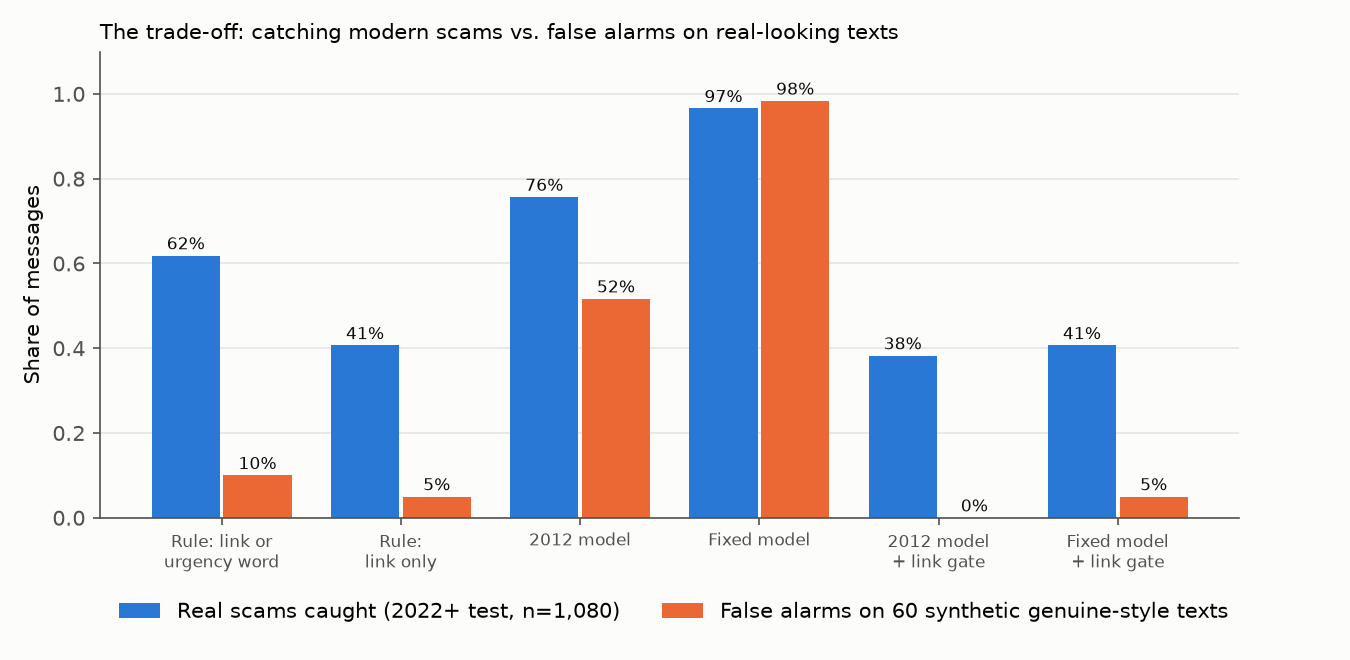

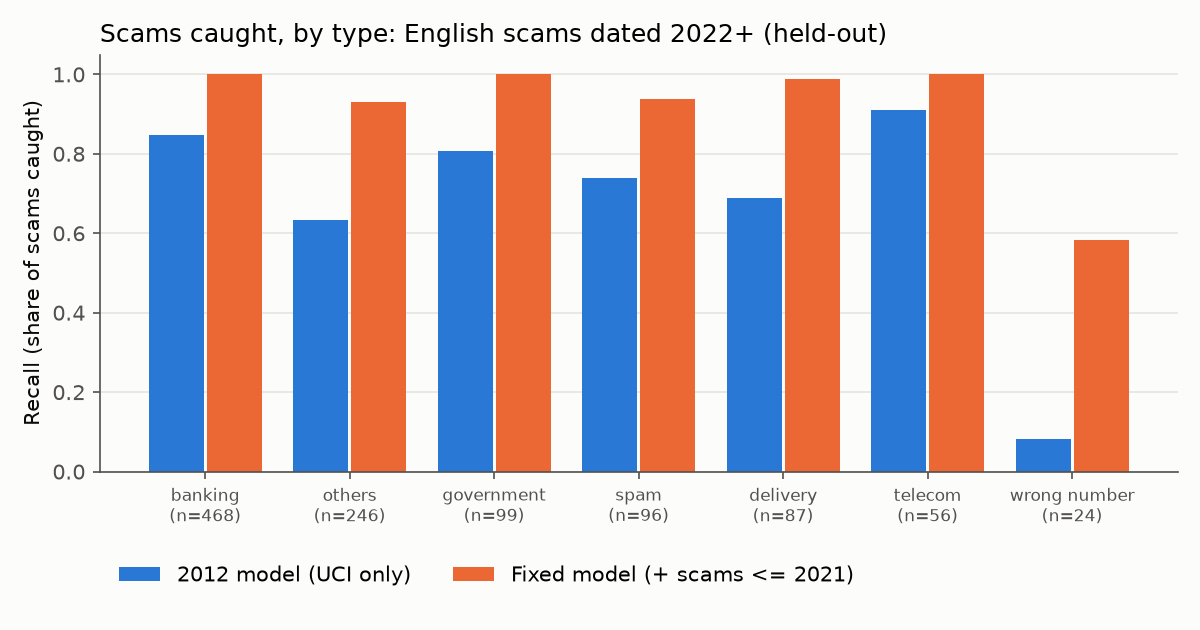

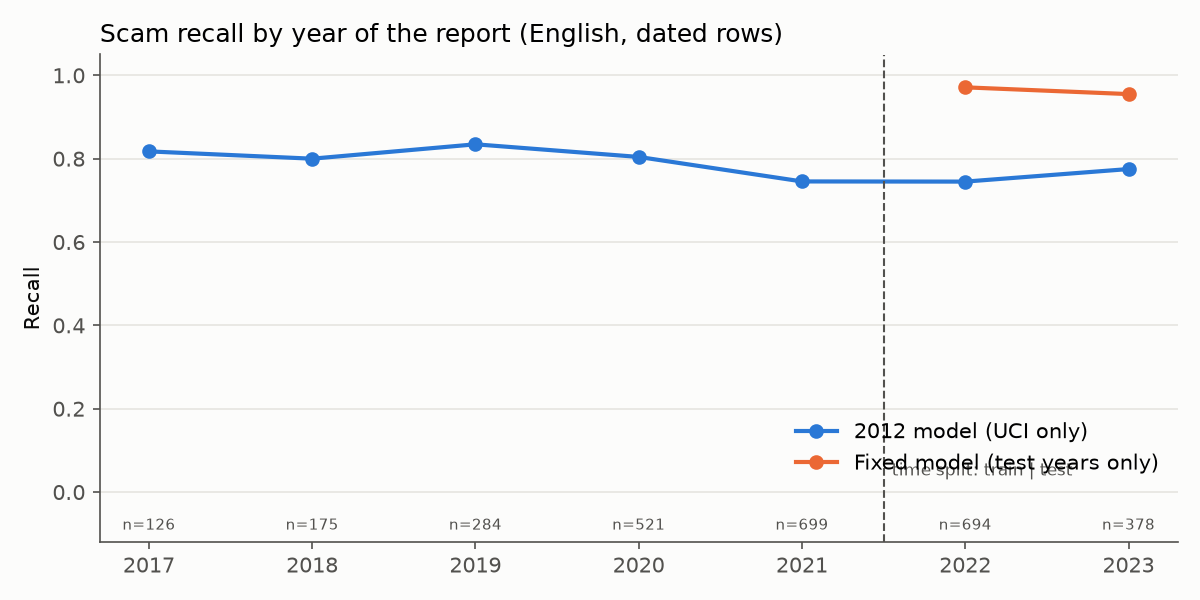

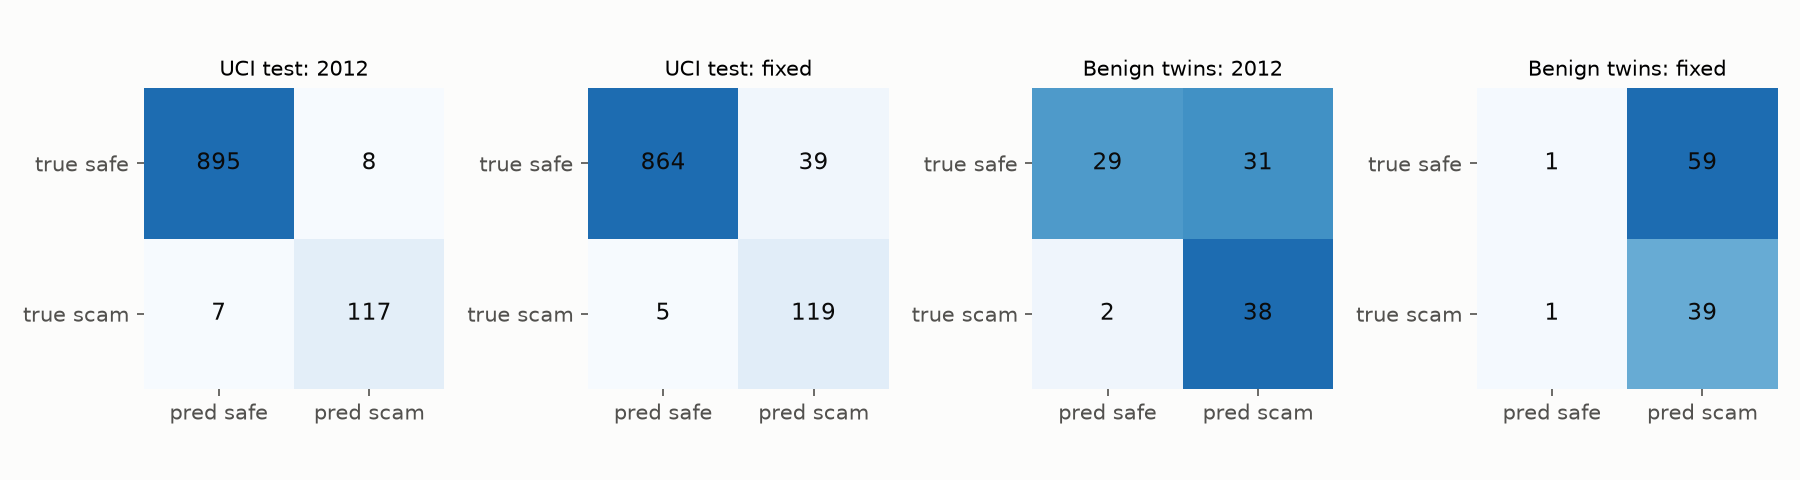

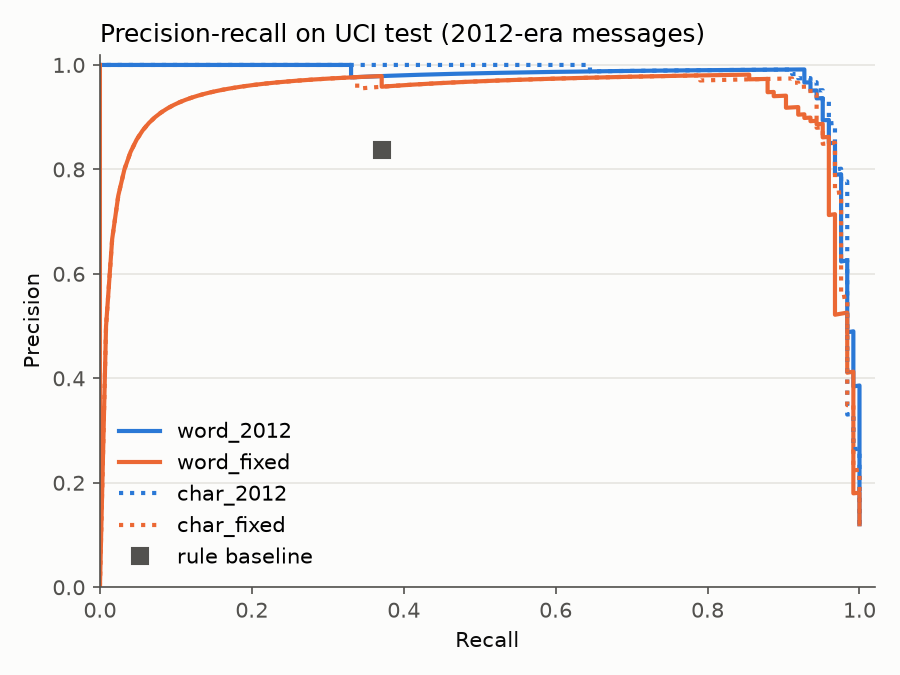

In [13]:
from IPython.display import Image, display
for f in ["tradeoff_catch_vs_false_alarm", "recall_by_scam_type", "recall_by_year", "confusion_matrices", "pr_curve_uci"]:
    display(Image(filename=str(FIGURES / (f + ".png")), width=760))

## 8. Where it fails
Per scam type, by message length (a small fairness-style check: we have no age or gender data, so we cannot check those), non-English messages, benign twins, missed scams and false alarms.

In [14]:
display(pd.read_csv(RESULTS / "recall_by_scam_type_late_test.csv"))
display(pd.read_csv(RESULTS / "by_length_bucket.csv"))
display(pd.read_csv(RESULTS / "nonenglish_by_language.csv"))
display(pd.read_csv(RESULTS / "benign_twins_by_category.csv"))

,scam_type,n,recall_rule,recall_word_2012,recall_char_2012,recall_word_fixed,recall_char_fixed,ci95_lo_word_2012,ci95_hi_word_2012,ci95_lo_word_fixed,ci95_hi_word_fixed
0,banking,468,0.7564,0.8483,0.7073,1.0000,1.0000,0.8130,0.8779,0.9919,1.0000
1,others,246,0.3902,0.6341,0.6585,0.9309,0.9187,0.5723,0.6918,0.8921,0.9564
2,government,99,0.7273,0.8081,0.7980,1.0000,1.0000,0.7196,0.8736,0.9626,1.0000
3,spam,96,0.5625,0.7396,0.7292,0.9375,0.9062,0.6438,0.8169,0.8703,0.9710
4,delivery,87,0.6552,0.6897,0.6322,0.9885,0.9885,0.5862,0.7771,0.9377,0.9980
5,telecom,56,0.6250,0.9107,0.8750,1.0000,1.0000,0.8074,0.9613,0.9358,1.0000
6,wrong number,24,0.0000,0.0833,0.0417,0.5833,0.4583,0.0232,0.2585,0.3883,0.7553
7,hey mum/dad,4,0.0000,0.0000,0.7500,0.2500,1.0000,0.0000,0.4899,0.0456,0.6994


,len_bucket,n,recall_rule,recall_word_2012,recall_char_2012,recall_word_fixed,recall_char_fixed,ci95_lo_word_2012,ci95_hi_word_2012,ci95_lo_word_fixed,ci95_hi_word_fixed,uci_ham_n,fa_word_2012,fa_word_fixed
0,a <80 chars,152,0.3158,0.4934,0.4671,0.8882,0.8355,0.4151,0.5721,0.8282,0.9290,628,0.0096,0.0446
1,b 80-159,644,0.6972,0.7873,0.6817,0.9860,0.9860,0.7540,0.8171,0.9737,0.9926,231,0.0043,0.0346
2,c 160-319,234,0.6068,0.8248,0.8333,0.9615,0.9701,0.7709,0.8681,0.9285,0.9796,36,0.0278,0.0833
3,d 320+,50,0.5800,0.8400,0.9000,0.9600,0.9600,0.7149,0.9166,0.8654,0.9890,8,0.0000,0.0000


,language,n,recall_raw_word_2012,recall_translation_word_2012,recall_raw_word_fixed,recall_translation_word_fixed
0,Spanish,3191,0.4810,0.6863,0.7255,0.9887
1,Dutch,1551,0.4919,0.7937,0.8685,0.9890
2,French,870,0.4667,0.7207,0.7644,0.9862
3,German,590,0.5339,0.6271,0.8051,0.9644
4,Italian,534,0.4345,0.6966,0.7022,0.9944
5,Indonesian,329,0.7234,0.6687,0.9058,0.9301
6,Portuguese,247,0.5628,0.7449,0.7409,0.9757
7,Japanese,173,0.3353,0.4566,0.3988,0.9711
8,Hindi,156,0.6282,0.6603,0.9103,0.9295
9,Malay,121,0.8843,0.8430,0.9504,0.9835


,label,category,n,flag_rule,flag_word_2012,flag_word_fixed,flag_char_fixed
0,0,bank_alert,10,0.0000,1.0000,1.0000,1.0000
1,0,bank_otp,10,0.2000,0.6000,1.0000,1.0000
2,0,delivery,10,0.1000,0.4000,1.0000,1.0000
3,0,medical,10,0.2000,0.4000,1.0000,0.9000
4,0,pharmacy,10,0.0000,0.3000,1.0000,1.0000
5,0,utility_other,10,0.1000,0.4000,0.9000,0.8000
6,1,bank_alert,7,0.8571,1.0000,1.0000,1.0000
7,1,bank_otp,7,0.7143,1.0000,1.0000,1.0000
8,1,delivery,7,1.0000,1.0000,1.0000,1.0000
9,1,medical,6,0.8333,1.0000,1.0000,1.0000


In [15]:
pd.set_option("display.max_colwidth", 160)
display(pd.read_csv(RESULTS / "fixed_model_missed_scams.csv").head(8))
display(pd.read_csv(RESULTS / "fixed_model_false_alarms.csv").head(8))

,year,scam_type,p_word_fixed,text,auto_reason
0,2022.0,spam,0.0022,"Ηello аll, guуsǃ I knоw, my mesѕаge maу bе toо sрeсifіc, Βut mу sіstеr fоund nісе <NAMED_ENTITY> and theу mаrrіed, ѕо how аbout me?! :) I аm 25 уеars оld, N...",no link and no urgency word; reads like an ordinary notice
1,2023.0,wrong number,0.0115,"Hi, <NAMED_ENTITY>, we talked about the contract last time, we can talk about it later.\nI just wanted to let you know this is the wrong number.\nAren't you...",conversational opener with no link or urgency word; the scam starts later in the chat
2,2023.0,wrong number,0.0222,How are you doing,conversational opener with no link or urgency word; the scam starts later in the chat
3,2022.0,wrong number,0.0247,"Hi Julanne long time no see, I'm <NAMED_ENTITY>, how are you doing?",conversational opener with no link or urgency word; the scam starts later in the chat
4,2023.0,others,0.0274,i'm really sorry if i'm wasting ur time i just want to ask u for a small help if u don't mind i need this free xbox game pass code from discord gifts if u d...,no link and no urgency word; reads like an ordinary notice
5,2023.0,others,0.0274,i'm really sorry if i'm wasting ur time i just want to ask u for a small help if u don't mind i need this free xbox game pass code from discord gifts if u d...,no link and no urgency word; reads like an ordinary notice
6,2023.0,others,0.0305,i'm really sorry if u i'm wasting ur time i just want to ask u for a small help if u don't mind i need this free xbox game pass code from discord gifts if u...,no link and no urgency word; reads like an ordinary notice
7,2022.0,others,0.0324,fine fr no parking,no link and no urgency word; reads like an ordinary notice


,source,p_word_fixed,text,top_scam_words,auto_reason
0,uci_test_ham,1.0000,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323,tok_url,"contains a link; the normaliser hides the domain, so an official link looks like a scam link"
1,benign_twins,0.9993,Reminder: your credit card payment of $85.00 is due on Nov 25. Log in to your app to pay. Do not reply to this message.,"your, tok_money, payment, reply, card",money amount plus account wording overlaps with payment scams
2,benign_twins,0.9980,Your return has been received. Your refund of $24.99 will appear on your card in 3-5 days.,"your, tok_money, tok_num, tok_num tok_num, card",money amount plus account wording overlaps with payment scams
3,benign_twins,0.9962,Low balance alert: Your checking account ending 5532 is below $100.00.,"tok_money, your, alert, account, tok_num",money amount plus account wording overlaps with payment scams
4,benign_twins,0.9951,"Direct deposit of $1,245.67 received in your checking account ending 5532.","tok_money, your, account, tok_num, received",money amount plus account wording overlaps with payment scams
5,benign_twins,0.9920,"Your pension payment of $1,512.00 was deposited today.","tok_money, your, payment, tok_date, of tok_money",money amount plus account wording overlaps with payment scams
6,benign_twins,0.9907,First Harbor Bank Fraud Alert: Did you use your card ending 4821 for $62.10 at Corner Grocery on Nov 3? Reply YES or NO. We will never ask for your PIN or c...,"your, tok_money, for, alert, reply",one-time code wording overlaps with modern banking scams
7,benign_twins,0.9890,Dental reminder: your cleaning is on Friday at 11 AM. Call 555-0142 to change it.,"tok_phone, tok_date, your, call tok_phone, on",promotional or call-to-action words typical of 2012 spam


## 9. Explanations
For any message: the top 5 n-grams pushing toward 'scam' (coefficient x tf-idf value). `friendly_explain` drops stop-word-only n-grams and writes tokens in plain words, as the demo does.

In [16]:
for t in ["Your package could not be delivered. Update your address here: http://parcel-help.com",
          "Maple Pharmacy: Your prescription is ready for pickup at our Main Street store."]:
    n = normalise(t)
    for name in ["word_2012", "word_fixed"]:
        p = models[name].predict_proba([n])[0, 1]
        print(f"{name:10s} p={p:.2f}", friendly_explain(models[name], n))
    print()

word_2012  p=0.72 [('[a web link]', 1.8239435838287108), ('your address', 0.49153566983952274), ('package', 0.24680673948474652), ('address', 0.2461750079023289), ('delivered', 0.21325260616839747)]
word_fixed p=1.00 [('[a web link]', 1.9339245118430146), ('package', 0.9953940651095666), ('update', 0.5753251093317369), ('your package', 0.5170125566578012), ('here [a web link]', 0.46034548420942706)]

word_2012  p=0.12 [('store', 0.15617084824438743), ('street', 0.0209946979694934)]
word_fixed p=0.59 [('is ready', 0.2643258296824079), ('main', 0.103257853570735), ('store', 0.09017708505953678), ('pickup', 0.0694086187909972), ('pickup at', 0.014495567308603286)]



## 10. Save models and metrics
Writes `models/*.joblib` and `results/metrics.json` (the README copies every number from this file).

In [17]:
save_models(models, thresholds)
metrics = write_metrics(d, shortcut, near, thresholds, M, tables, t0)
print("saved; runtime_seconds =", metrics["runtime_seconds"])

saved; runtime_seconds = 23.9
